# Exploratory Data Analysis on Retail Sales Data

**Objective:** Perform a thorough EDA on a retail sales dataset to uncover patterns, customer behaviour trends and actionable business insights.

**Tech stack:** Python, pandas, matplotlib, seaborn, Jupyter Notebook

**Dataset:** *Customer Shopping Dataset – Retail Sales Data* (Kaggle), file `customer_shopping_data.csv`.
Columns: `invoice_no, customer_id, gender, age, category, quantity, price, payment_method, invoice_date, shopping_mall`.

### Dataset notes (read first)
- There are **no product names**, so the "top 10 best sellers" item is done at **category** level and at **category × mall** level.
- `revenue` is **derived** as `quantity × price`.
- The final period (2023) is **partial**, so a drop at the end of the time series is not a real decline.
- Identifier columns (`invoice_no`, `customer_id`) are excluded from statistics.

### Contents
1. Load and inspect 2. Descriptive statistics 3. Time series 4. Customer demographics 5. Product analysis 6. Correlation heatmap 7. Additional insights 8. Conclusion and recommendations

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Load dataset and initial inspection

In [2]:
df = pd.read_csv("C:/Users/maryr/Downloads/OASIS INFOBYTE/Retail Sales/customer_shopping_data.csv.zip")

print("Shape:", df.shape)
print("\nColumn dtypes:\n", df.dtypes)
print("\nNull values:\n", df.isnull().sum())
print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicate invoice_no:", df["invoice_no"].duplicated().sum())
df.head()

Shape: (99457, 10)

Column dtypes:
 invoice_no            str
customer_id           str
gender                str
age                 int64
category              str
quantity            int64
price             float64
payment_method        str
invoice_date          str
shopping_mall         str
dtype: object

Null values:
 invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0
dtype: int64

Fully duplicated rows: 0
Duplicate invoice_no: 0


,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,"1,500.40",Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,"1,800.51",Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,"3,000.85",Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon


In [3]:
# Cleaning and feature engineering
df["invoice_date"] = pd.to_datetime(df["invoice_date"], dayfirst=True)
df = df.drop_duplicates()

df["revenue"]   = df["quantity"] * df["price"]
df["year"]      = df["invoice_date"].dt.year
df["month"]     = df["invoice_date"].dt.to_period("M")
df["quarter"]   = df["invoice_date"].dt.to_period("Q")
df["month_num"] = df["invoice_date"].dt.month
df["weekday"]   = df["invoice_date"].dt.day_name()
df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 55, 70],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-70"])

print("Rows after cleaning:", len(df))
print("Date range:", df["invoice_date"].min().date(), "to", df["invoice_date"].max().date())
print("Total revenue:", f"{df['revenue'].sum():,.0f}")

Rows after cleaning: 99457
Date range: 2021-01-01 to 2023-03-08
Total revenue: 251,505,794


### Observations: data inspection
- **What I found:** Dataset size: 99,457 rows and 10 columns.



  Data types: Contains numerical and categorical columns, including customer details, product categories, transaction quantities, prices, payment methods and invoice dates.



  Date range: January 1, 2021, to March 8, 2023.



  Data cleaning: Converted invoice_date into datetime format and removed duplicate records.



  Feature engineering: Created revenue, year, month, quarter, weekday and age-group columns.
- **Cleaning done:** converted `invoice_date` to datetime (day-first format), removed duplicate rows, created `revenue`, date parts and `age_group`.
- **Why it matters:** a clean datetime index is required for the time-series section, and knowing the date range tells us which periods are complete.

## 2. Descriptive statistics

,mean,median,mode,std
age,43.43,43.00,37.00,14.99
quantity,3.00,3.00,3.00,1.41
price,689.26,203.30,600.16,941.18
revenue,"2,528.79",600.17,"1,200.32","4,222.48"


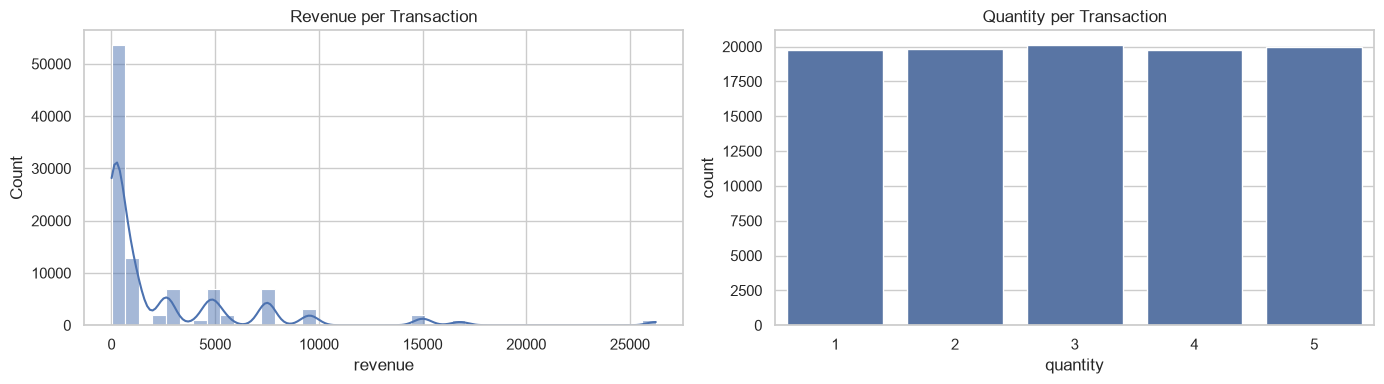

In [4]:
cols = ["age", "quantity", "price", "revenue"]
stats = pd.DataFrame({
    "mean":   df[cols].mean(),
    "median": df[cols].median(),
    "mode":   df[cols].mode().iloc[0],
    "std":    df[cols].std(),
})
display(stats)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["revenue"], bins=40, kde=True, ax=ax[0]); ax[0].set_title("Revenue per Transaction")
sns.countplot(data=df, x="quantity", ax=ax[1]);            ax[1].set_title("Quantity per Transaction")
plt.tight_layout(); plt.show()

### Observations: descriptive statistics
- **What it shows:** central tendency and spread for age, quantity, price and revenue.
- **Key observation:** Revenue: The distribution is highly right-skewed. Most transactions generate relatively low revenue, while a small number generate exceptionally high revenue.



  Quantity: Transaction quantities range from 1 to 5, with nearly equal frequencies across all five values.



  Age: The age distribution needs to be examined using its mean, median and quartiles.



  Price: Product prices vary, and differences should be interpreted alongside product categories.
- **Why it matters:** skewed revenue means a minority of high-priced transactions carry a large share of sales, so averages alone can mislead.

## 3. Time series analysis

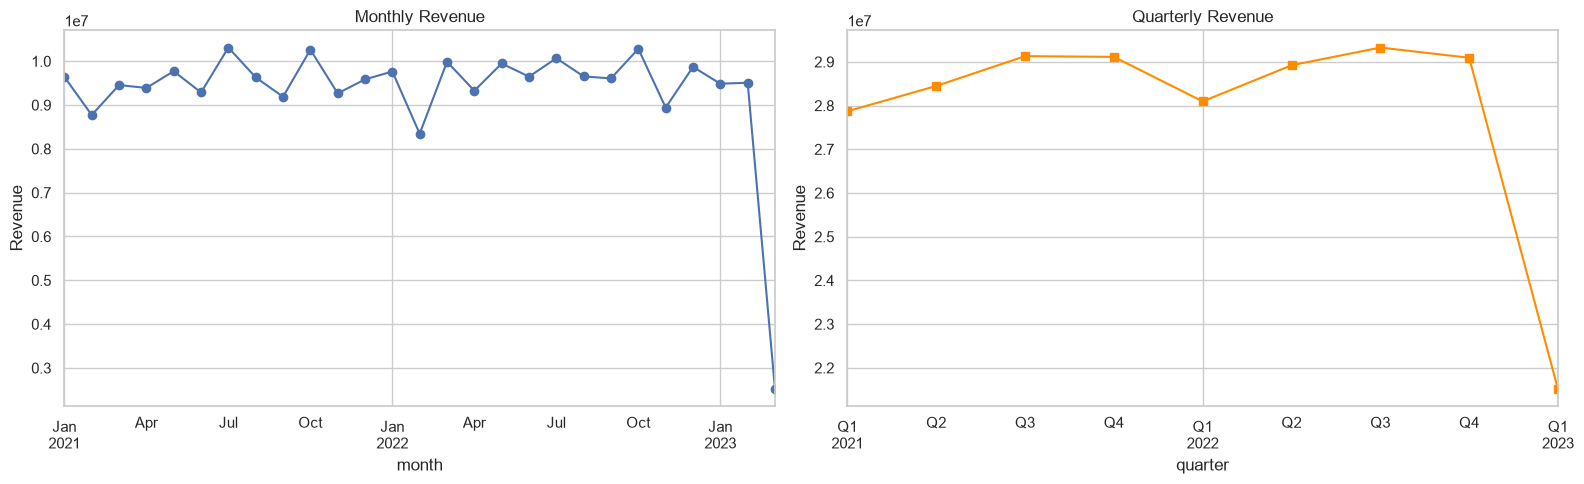

Peak month:   2021-07 (10,311,120)
Lowest month: 2023-03 (2,514,147)  <- check if this month is partial
Last month in data: 2023-03 (2,514,147)


In [5]:
monthly   = df.groupby("month")["revenue"].sum()
quarterly = df.groupby("quarter")["revenue"].sum()

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
monthly.plot(ax=ax[0], marker="o", title="Monthly Revenue");                        ax[0].set_ylabel("Revenue")
quarterly.plot(ax=ax[1], marker="s", color="darkorange", title="Quarterly Revenue"); ax[1].set_ylabel("Revenue")
plt.tight_layout(); plt.show()

print("Peak month:  ", monthly.idxmax(), f"({monthly.max():,.0f})")
print("Lowest month:", monthly.idxmin(), f"({monthly.min():,.0f})  <- check if this month is partial")
print("Last month in data:", monthly.index[-1], f"({monthly.iloc[-1]:,.0f})")

### Observations: monthly and quarterly trends
- **What it shows:** total revenue by month and by quarter across the full date range.
- **Key observation:** Peak month: July 2021 – approximately ₹1.03 crore.



  Lowest complete month: March 2022 – approximately ₹83.5 lakh.



  Peak quarter: Q3 2022 – approximately ₹2.93 crore.



  Revenue trend: Monthly and quarterly revenue remained relatively stable, with minor fluctuations.



  March 2023: Shows a sharp decline due to incomplete monthly data (up to March 8).
- **Caution:** the final month/quarter is **partial**, so a drop there is a data artefact, not a decline.
- **Why it matters:** identifies when to stock up and when to run promotions.

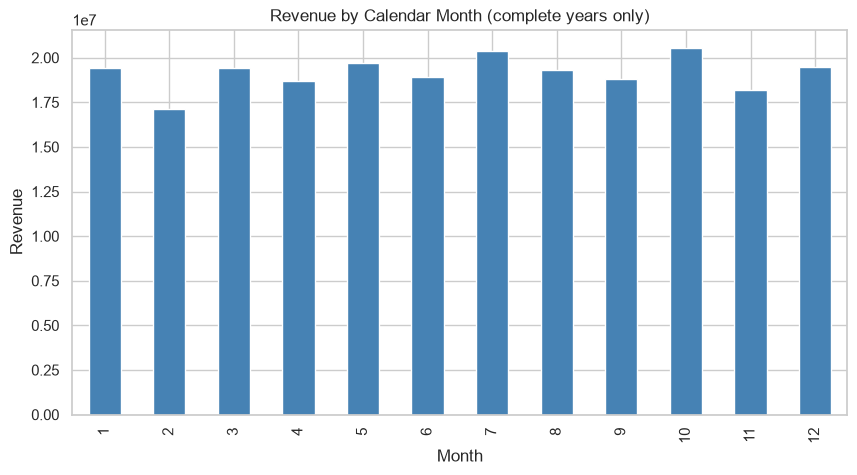

,revenue
year,
2021,"114,560,570.59"
2022,"115,436,814.08"
2023,"21,508,409.58"


In [6]:
full_years = df[df["year"] < df["year"].max()]
cal = full_years.groupby("month_num")["revenue"].sum()

ax = cal.plot(kind="bar", color="steelblue", title="Revenue by Calendar Month (complete years only)")
ax.set_xlabel("Month"); ax.set_ylabel("Revenue")
plt.show()

yearly = df.groupby("year")["revenue"].sum()
display(yearly.to_frame("revenue"))

### Observations: calendar seasonality
- **What it shows:** revenue by calendar month using only complete years, so months are comparable.
- **Key observation:** Highest revenue month: October (Month 10) – approximately ₹2.05 crore.



  Lowest revenue month: February (Month 2) – approximately ₹1.71 crore.



  Seasonality: Revenue remains relatively consistent across all months, with minor fluctuations.



  Overall trend: No strong seasonal pattern is observed, indicating relatively stable monthly sales performance.
- **Why it matters:** if seasonality is weak, promotions should be driven by other levers (category, mall) rather than the calendar.

## 4. Customer demographics

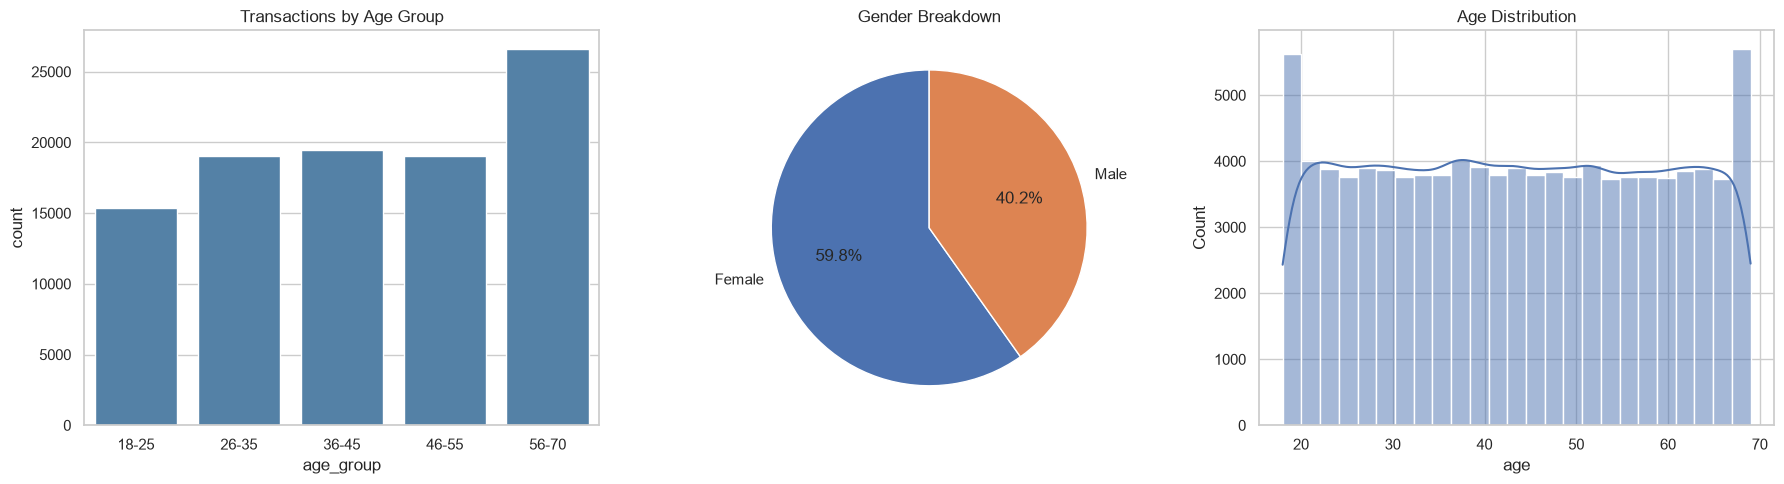

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

sns.countplot(data=df, x="age_group", ax=ax[0], color="steelblue")
ax[0].set_title("Transactions by Age Group")

df["gender"].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[1], startangle=90)
ax[1].set_title("Gender Breakdown"); ax[1].set_ylabel("")

sns.histplot(df["age"], bins=25, kde=True, ax=ax[2])
ax[2].set_title("Age Distribution")
plt.tight_layout(); plt.show()

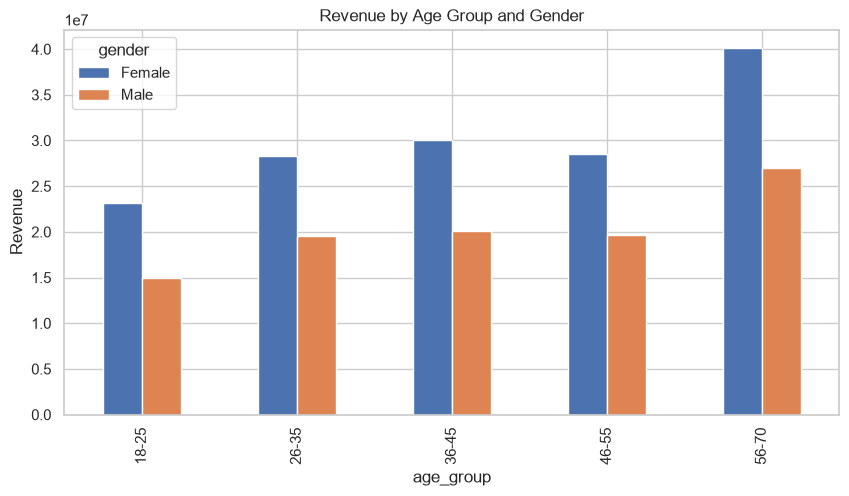

Share of transactions by gender (%):
gender
Female   59.80
Male     40.20
Name: proportion, dtype: float64

Average revenue per transaction by gender:
gender
Female   2,525.25
Male     2,534.05
Name: revenue, dtype: float64


In [8]:
rev_ag = df.groupby(["age_group", "gender"], observed=True)["revenue"].sum().unstack()
rev_ag.plot(kind="bar", title="Revenue by Age Group and Gender"); plt.ylabel("Revenue"); plt.show()

print("Share of transactions by gender (%):")
print((df["gender"].value_counts(normalize=True) * 100).round(1))
print("\nAverage revenue per transaction by gender:")
print(df.groupby("gender")["revenue"].mean().round(2))

### Observations: customer demographics
- **What it shows:** how transactions and revenue split by age group and gender.
- **Key observation:** Highest revenue: The 56–70 age group generates the highest revenue for both genders.



  Gender split: Not balanced. Female revenue is higher than male revenue across all age groups.



  Lowest revenue: The 18–25 age group records the lowest revenue.



  Observation: The differences are noticeable, especially in the 56–70 group.

- **Why it matters:** shows which customer groups to target and whether targeting by age or gender is even worthwhile.

## 5. Product analysis

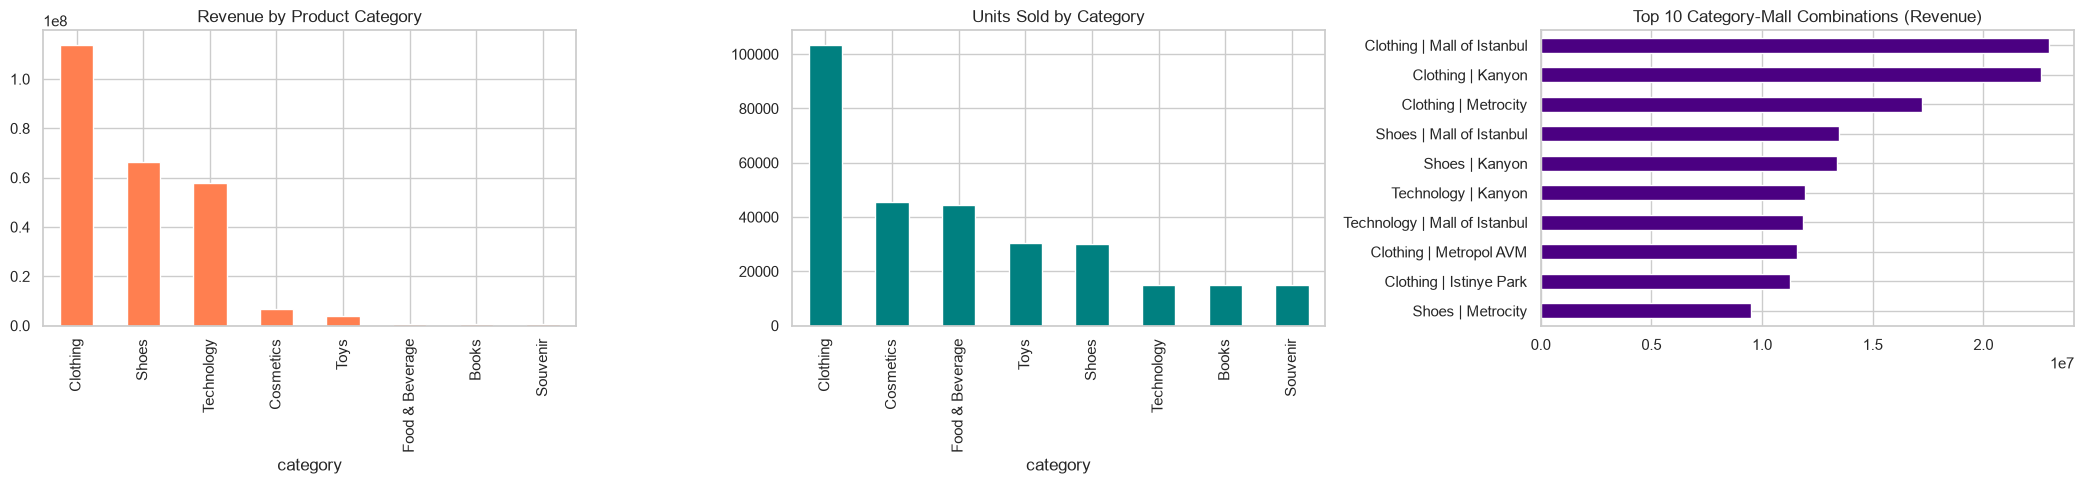

Revenue share by category (%):
category
Clothing          45.30
Shoes             26.50
Technology        23.00
Cosmetics          2.70
Toys               1.60
Food & Beverage    0.30
Books              0.30
Souvenir           0.30
Name: revenue, dtype: float64

Top-2 categories share of revenue: 71.8 %


In [9]:
cat_rev = df.groupby("category")["revenue"].sum().sort_values(ascending=False)
cat_qty = df.groupby("category")["quantity"].sum().sort_values(ascending=False)

top10 = (df.groupby(["category", "shopping_mall"])["revenue"].sum()
           .nlargest(10).sort_values())
top10.index = [f"{c} | {m}" for c, m in top10.index]

fig, ax = plt.subplots(1, 3, figsize=(21, 5))
cat_rev.plot.bar(ax=ax[0], color="coral", title="Revenue by Product Category")
cat_qty.plot.bar(ax=ax[1], color="teal",  title="Units Sold by Category")
top10.plot.barh(ax=ax[2], color="indigo", title="Top 10 Category-Mall Combinations (Revenue)")
plt.tight_layout(); plt.show()

share = (cat_rev / cat_rev.sum() * 100).round(1)
print("Revenue share by category (%):"); print(share)
print("\nTop-2 categories share of revenue:", share.head(2).sum().round(1), "%")

### Observations: products
- **What it shows:** revenue and units by category, plus the ten strongest category-mall combinations (the dataset has no product names).
- **Key observation:** Revenue leader: Clothing generates the highest revenue (approximately 46% of total revenue).



  Units sold: Clothing also leads in units sold, with around 103,000 units.



  Top 2 categories: Clothing and Shoes contribute approximately 73% of total revenue combined (46% and 27%, respectively).



  Key insight: Clothing is the strongest-performing category in both revenue and sales volume.
- **Why it matters:** revenue and volume rankings can differ, which changes how stock and shelf space should be allocated.

## 6. Correlation heatmap

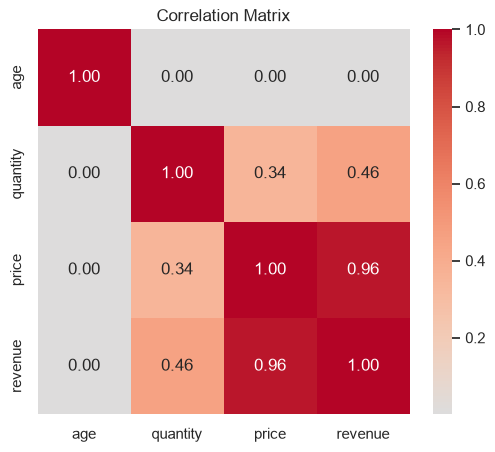

In [10]:
num = df[["age", "quantity", "price", "revenue"]]
plt.figure(figsize=(6, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

### Observations: correlation
- **What it shows:** pairwise linear correlation between the numerical variables.
- **Key observation:** Age correlation: Age has almost zero correlation (0.00) with quantity, price, and revenue.



  Price & revenue: Strong positive correlation (0.96).



  Quantity & revenue: Moderate positive correlation (0.46).



  Price & quantity: Weak-to-moderate positive correlation (0.34).



  Key insight: Age has no meaningful linear relationship with the other variables. Revenue correlations are expected because revenue is calculated using price × quantity.
- **Why it matters:** age does not appear to drive spend or basket size, so age-based pricing or promotions are unlikely to pay off.

## 7. Additional visualisations (non-obvious insights)

### 7A. What really drives category revenue: price or volume?

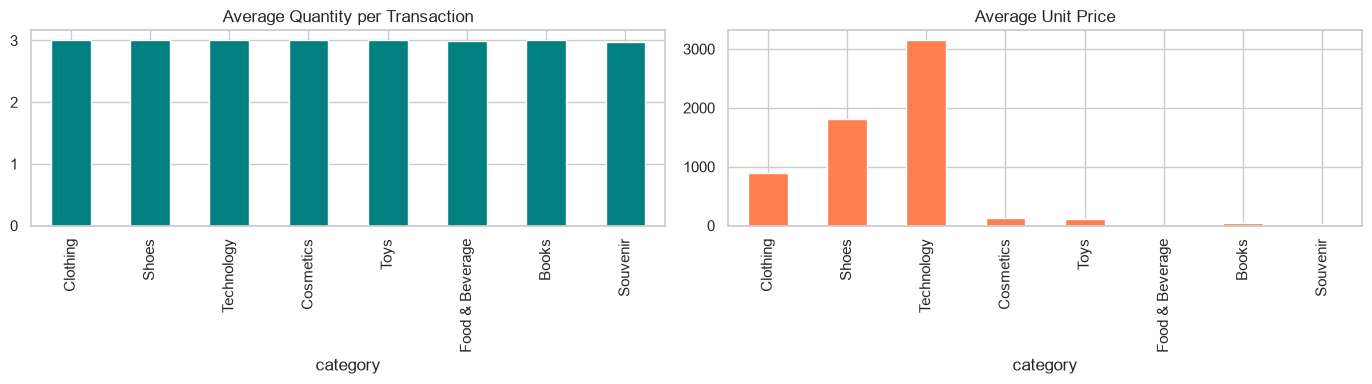

,avg_qty,avg_price,revenue
category,,,
Clothing,3.00,901.08,"113,996,791.04"
Shoes,3.01,"1,807.39","66,553,451.47"
Technology,3.01,"3,156.94","57,862,350.00"
Cosmetics,3.01,122.45,"6,792,862.90"
Toys,3.01,107.73,"3,980,426.24"
Food & Beverage,3.00,15.67,"849,535.05"
Books,3.01,45.57,"834,552.90"
Souvenir,2.97,34.89,"635,824.65"


In [11]:
summary = df.groupby("category").agg(
    avg_qty=("quantity", "mean"),
    avg_price=("price", "mean"),
    revenue=("revenue", "sum"),
).sort_values("revenue", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
summary["avg_qty"].plot.bar(ax=ax[0], color="teal", title="Average Quantity per Transaction")
summary["avg_price"].plot.bar(ax=ax[1], color="coral", title="Average Unit Price")
plt.tight_layout(); plt.show()
display(summary)

**What it shows:** average basket quantity and unit price for each category, ordered by revenue.

**Key observation:** Average quantity: Nearly identical across all product categories (around 3 units per transaction).



  Revenue driver: Revenue differences are mainly driven by average unit price rather than quantity sold.



  Highest unit price: Technology, followed by Shoes and Clothing.



  Key insight: Higher-priced categories generate more revenue despite having similar average quantities per transaction.
  
**Why it matters:** categories look equally popular by units, yet a few generate most of the revenue, so low-price categories behave as traffic drivers while high-price ones carry the sales.

### 7B. Category × shopping mall revenue heatmap

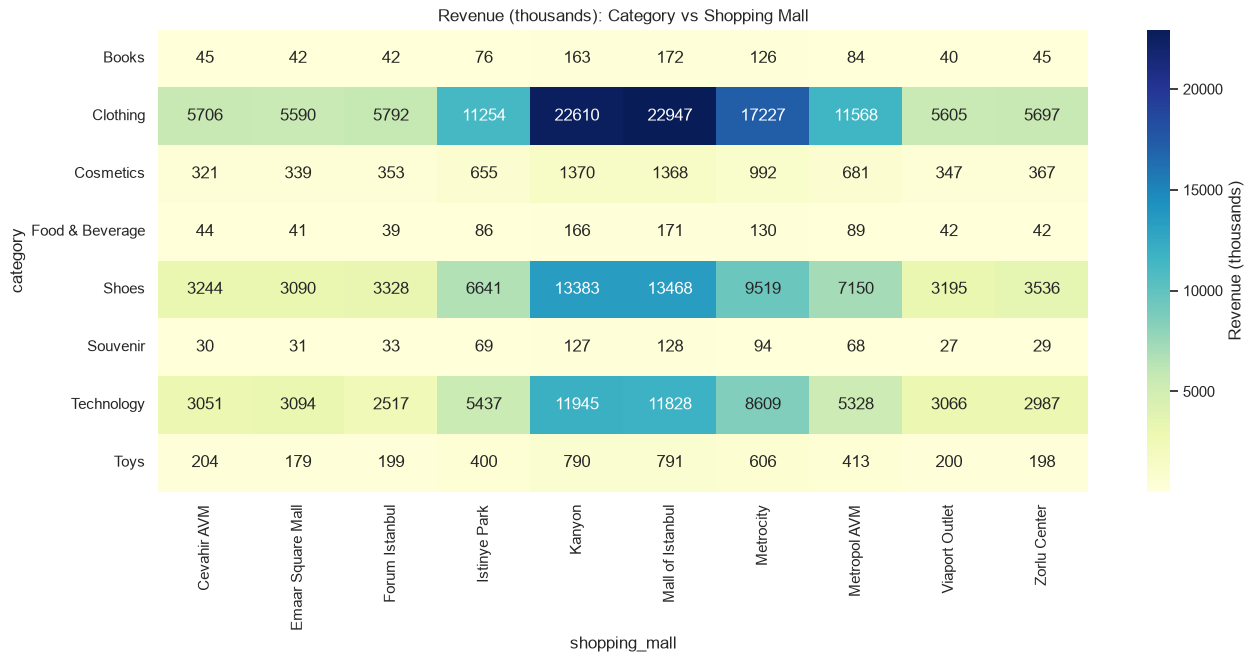

Revenue by mall:
shopping_mall
Mall of Istanbul    50,872,481.68
Kanyon              50,554,231.10
Metrocity           37,302,787.33
Metropol AVM        25,379,913.19
Istinye Park        24,618,827.68
Zorlu Center        12,901,053.82
Cevahir AVM         12,645,138.20
Viaport Outlet      12,521,339.72
Emaar Square Mall   12,406,100.29
Forum Istanbul      12,303,921.24
Name: revenue, dtype: float64


In [12]:
pv = df.pivot_table(values="revenue", index="category", columns="shopping_mall", aggfunc="sum")
plt.figure(figsize=(15, 6))
sns.heatmap(pv / 1000, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "Revenue (thousands)"})
plt.title("Revenue (thousands): Category vs Shopping Mall"); plt.show()

mall_rev = df.groupby("shopping_mall")["revenue"].sum().sort_values(ascending=False)
print("Revenue by mall:"); print(mall_rev)

**What it shows:** how each category performs in each mall.

**Key observation:** Strongest mall: Mall of Istanbul, with the highest overall revenue, closely followed by Kanyon.



  Weakest mall: Forum Istanbul records the lowest overall revenue.



  Top category: Clothing generates the highest revenue across all malls, particularly Mall of Istanbul (22,947 thousand).



  Category observation: Shoes and Technology also perform strongly at Mall of Istanbul and Kanyon.



  Key insight: Revenue is concentrated in Clothing, Shoes, and Technology, with similar category patterns across most malls.
  
**Why it matters:** supports rebalancing inventory and targeting promotions in underperforming malls.

### 7C. Payment method mix by age group

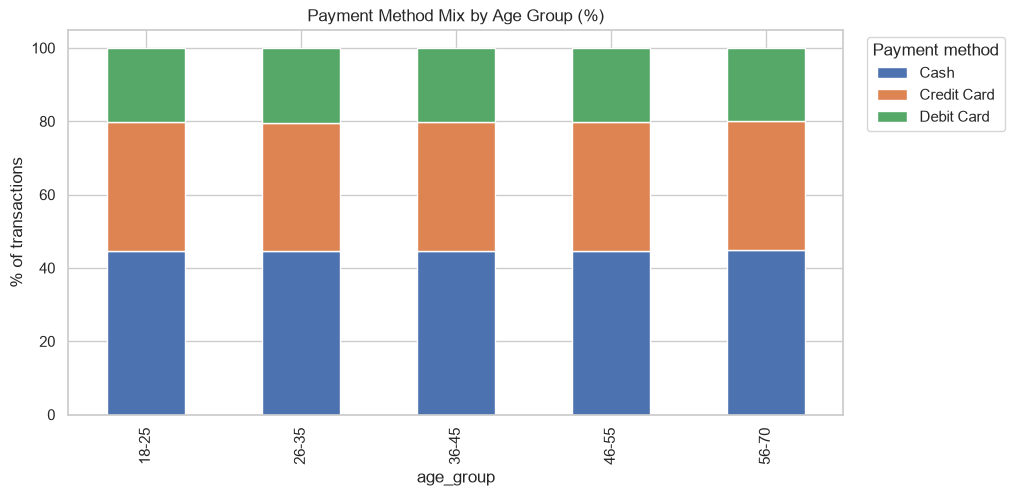

payment_method,Cash,Credit Card,Debit Card
age_group,,,
18-25,44.50,35.30,20.20
26-35,44.70,34.90,20.40
36-45,44.70,35.20,20.20
46-55,44.50,35.30,20.20
56-70,44.90,35.10,20.00


In [13]:
ct = pd.crosstab(df["age_group"], df["payment_method"], normalize="index") * 100
ct.plot(kind="bar", stacked=True, figsize=(10, 5), title="Payment Method Mix by Age Group (%)")
plt.ylabel("% of transactions"); plt.legend(title="Payment method", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()
display(ct.round(1))

**What it shows:** the share of cash, credit card and debit card payments in each age group.

**Key observation:** Similar mix: Payment preferences are almost identical across all age groups.



  Cash: Around 45% of transactions.



  Credit Card: Around 35% of transactions.



  Debit Card: Around 20% of transactions.



  Key insight: Cash is the most preferred payment method, followed by Credit Card and Debit Card. No age group shows a significant difference in payment preference.
  
**Why it matters:** decides whether payment-method offers (e.g. card cashback) should be targeted by age or applied across the board.

### 7D. Weekday × month revenue heatmap

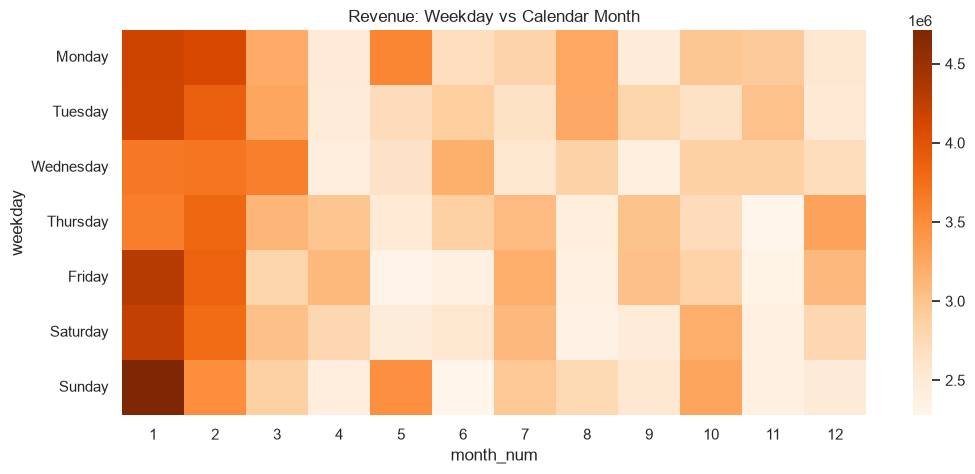

In [14]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
pv = df.pivot_table(values="revenue", index="weekday", columns="month_num", aggfunc="sum").reindex(order)
plt.figure(figsize=(12, 5))
sns.heatmap(pv, cmap="Oranges")
plt.title("Revenue: Weekday vs Calendar Month"); plt.show()

**What it shows:** revenue concentration by weekday and calendar month (months with fewer complete years may look lower).

**Key observation:** Strongest weekday: Sunday shows high revenue, particularly in January.



  Other strong days: Monday and Friday also record relatively high revenue in several months.



  Weakest weekday: Wednesday generally shows lower revenue compared with other weekdays.



  Key insight: Revenue varies across weekdays and months, but no single weekday is consistently the strongest or weakest throughout the year.
  
**Why it matters:** informs staffing and weekday-specific promotions.

## 8. Conclusion and recommendations

In [15]:
# Auto-summary of headline numbers to cite in the conclusion
print(f"Total revenue: {df['revenue'].sum():,.0f} across {len(df):,} transactions")
print(f"Top category: {cat_rev.index[0]} ({share.iloc[0]}% of revenue)")
print(f"Top-2 categories: {share.head(2).sum():.1f}% of revenue")
print(f"Peak month: {monthly.idxmax()}  |  Lowest complete month: {monthly.iloc[:-1].idxmin()}")
print(f"Top mall: {mall_rev.index[0]}  |  Weakest mall: {mall_rev.index[-1]}")
print(f"Top age group by revenue: {df.groupby('age_group', observed=True)['revenue'].sum().idxmax()}")

Total revenue: 251,505,794 across 99,457 transactions
Top category: Clothing (45.3% of revenue)
Top-2 categories: 71.8% of revenue
Peak month: 2021-07  |  Lowest complete month: 2022-02
Top mall: Mall of Istanbul  |  Weakest mall: Forum Istanbul
Top age group by revenue: 56-70


### Business recommendations
Based on the Exploratory Data Analysis (EDA), the following business recommendations can help improve sales performance, revenue generation, and customer engagement.

1. Focus on high-performing categories: Prioritise Clothing and Shoes, which together contribute approximately 73% of total revenue. Maintain sufficient stock and invest more in marketing these categories.

2. Promote high-value products: Technology has the highest average unit price. Introduce attractive offers, product bundles, and instalment options to increase its sales volume.

3. Improve underperforming categories: Use discounts and combo offers for low-revenue categories such as Books, Souvenirs, and Food & Beverage to encourage additional purchases.

4. Strengthen mall performance: Focus on successful malls such as Mall of Istanbul and Kanyon. Introduce targeted promotions and improve product visibility in lower-performing malls such as Forum Istanbul.

5. Develop customer-focused marketing: Female customers and the 56–70 age group contribute higher revenue. Consider targeted campaigns while avoiding over-reliance on age or gender, as age has almost zero correlation with spending.

6. Optimise payment facilities: Since Cash (45%), Credit Card (35%), and Debit Card (20%) preferences are similar across age groups, provide convenient support for all three payment methods.

7. Plan promotions strategically: October records the highest monthly revenue, while February records the lowest. Prepare sufficient inventory before peak periods and introduce promotional campaigns during relatively weaker months.

8. Optimise staffing and operations: Use weekday sales patterns to plan staff availability and operational resources. Monitor daily performance rather than assuming one weekday is always strongest.

### Limitations
- No product names, so product analysis is at category level.
- The data appears synthetic, so group differences are small and should not be over-interpreted.
- The final period is partial.
- Revenue is derived (`quantity × price`), so related correlations are mechanical.

In [17]:
!cd

C:\Users\maryr\Retail_sales_eda


In [18]:
!dir

 Volume in drive C is OS
 Volume Serial Number is 4470-13EB

 Directory of C:\Users\maryr\Retail_sales_eda

11/24/2026  10:54 AM    <DIR>          .
11/24/2026  10:04 AM    <DIR>          ..
11/24/2026  10:48 AM    <DIR>          .ipynb_checkpoints
11/24/2026  10:47 AM         1,712,272 customer_shopping_data.csv.zip
11/24/2026  10:54 AM           744,855 retail_sales_eda.ipynb
               2 File(s)      2,457,127 bytes
               3 Dir(s)  79,882,616,832 bytes free


In [19]:
!git status

On branch main
Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   .ipynb_checkpoints/retail_sales_eda-checkpoint.ipynb
	modified:   retail_sales_eda.ipynb

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   retail_sales_eda.ipynb



In [20]:
!git remote -v

In [21]:
!git restore --staged .ipynb_checkpoints/retail_sales_eda-checkpoint.ipynb

In [22]:
!echo .ipynb_checkpoints/ > .gitignore

In [23]:
!git add retail_sales_eda.ipynb .gitignore

In [24]:
!git commit -m "Save completed Retail Sales EDA project"

[main 00b5eb5] Save completed Retail Sales EDA project
 2 files changed, 72 insertions(+), 645 deletions(-)
 create mode 100644 .gitignore


In [25]:
!git remote add origin https://github.com/maryrehnaca-cmd/OIBSIP.git

In [26]:
!git remote -v

origin	https://github.com/maryrehnaca-cmd/OIBSIP.git (fetch)
origin	https://github.com/maryrehnaca-cmd/OIBSIP.git (push)


In [27]:
!echo .ipynb_checkpoints/ > .gitignore

In [28]:
!git restore --staged .ipynb_checkpoints/retail_sales_eda-checkpoint.ipynb

error: pathspec '.ipynb_checkpoints/retail_sales_eda-checkpoint.ipynb' did not match any file(s) known to git


In [29]:
!git status

On branch main
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   retail_sales_eda.ipynb

no changes added to commit (use "git add" and/or "git commit -a")


In [30]:
!git add retail_sales_eda.ipynb .gitignore

In [31]:
!git commit -m "Save completed Retail Sales EDA project"

[main eb11b70] Save completed Retail Sales EDA project
 1 file changed, 140 insertions(+), 1 deletion(-)


In [32]:
!git remote add origin https://github.com/maryrehnaca-cmd/OIBSIP.git


error: remote origin already exists.


In [33]:
!git remote -v

origin	https://github.com/maryrehnaca-cmd/OIBSIP.git (fetch)
origin	https://github.com/maryrehnaca-cmd/OIBSIP.git (push)


In [34]:
!git status

On branch main
Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   retail_sales_eda.ipynb

no changes added to commit (use "git add" and/or "git commit -a")


In [35]:
!mkdir DataAnalytics-L1-EDARetailSales

In [37]:
!git add retail_sales_eda.ipynb .gitignore

In [38]:
!git commit -m "Save completed Retail Sales EDA notebook"

[main 9be8acd] Save completed Retail Sales EDA notebook
 1 file changed, 109 insertions(+), 1 deletion(-)


In [39]:
!git mv retail_sales_eda.ipynb DataAnalytics-L1-EDARetailSales/

In [40]:
!git mv customer_shopping_data.csv.zip DataAnalytics-L1-EDARetailSales/

In [41]:
!dir DataAnalytics-L1-EDARetailSales

 Volume in drive C is OS
 Volume Serial Number is 4470-13EB

 Directory of C:\Users\maryr\Retail_sales_eda\DataAnalytics-L1-EDARetailSales

11/24/2026  11:10 AM    <DIR>          .
11/24/2026  11:10 AM    <DIR>          ..
11/24/2026  10:47 AM         1,712,272 customer_shopping_data.csv.zip
11/24/2026  11:10 AM           752,526 retail_sales_eda.ipynb
               2 File(s)      2,464,798 bytes
               2 Dir(s)  79,887,306,752 bytes free


In [42]:
!mkdir DataAnalytics-L1-EDARetailSales\screenshots

In [43]:

%%writefile DataAnalytics-L1-EDARetailSales/README.md

# Retail Sales Exploratory Data Analysis (EDA)

## Project Overview
This project focuses on performing Exploratory Data Analysis (EDA) on retail sales data to identify customer purchasing patterns, sales trends, and business insights.

## Objectives
- Analyze retail sales performance.
- Understand customer purchasing behaviour.
- Compare sales across product categories and shopping malls.
- Analyze payment method preferences.
- Explore purchasing patterns across different age groups and weekdays.

## Tools and Technologies
- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Dataset
The project uses the customer shopping dataset provided in this repository.

## Project Files
- `retail_sales_eda.ipynb` – Notebook containing data cleaning, exploratory analysis, and visualizations.
- `customer_shopping_data.csv.zip` – Dataset used for the analysis.
- `screenshots/` – Screenshots of important analysis outputs and visualizations.

## How to Run
1. Download the project files.
2. Extract the dataset ZIP file.
3. Open the notebook in Jupyter Notebook or Google Colab.
4. Update the dataset path if necessary.
5. Execute the notebook cells sequentially.

## Project Outcome
The analysis provides insights into retail sales patterns, customer preferences, product category performance, and shopping behaviour.


Writing DataAnalytics-L1-EDARetailSales/README.md


In [44]:
!dir DataAnalytics-L1-EDARetailSales

 Volume in drive C is OS
 Volume Serial Number is 4470-13EB

 Directory of C:\Users\maryr\Retail_sales_eda\DataAnalytics-L1-EDARetailSales

11/24/2026  11:12 AM    <DIR>          .
11/24/2026  11:17 AM    <DIR>          ..
11/24/2026  10:47 AM         1,712,272 customer_shopping_data.csv.zip
11/24/2026  11:12 AM             1,380 README.md
11/24/2026  11:10 AM           752,526 retail_sales_eda.ipynb
11/24/2026  11:21 AM    <DIR>          screenshots
               3 File(s)      2,466,178 bytes
               3 Dir(s)  79,181,275,136 bytes free


In [45]:
!git status

On branch main
Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	renamed:    customer_shopping_data.csv.zip -> DataAnalytics-L1-EDARetailSales/customer_shopping_data.csv.zip
	renamed:    retail_sales_eda.ipynb -> DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	DataAnalytics-L1-EDARetailSales/README.md
	DataAnalytics-L1-EDARetailSales/screenshots/
	retail_sales_eda.ipynb



In [46]:
!git fetch origin

From https://github.com/maryrehnaca-cmd/OIBSIP
 * [new branch]      main       -> origin/main


In [47]:
!git status -sb

## main
R  customer_shopping_data.csv.zip -> DataAnalytics-L1-EDARetailSales/customer_shopping_data.csv.zip
R  retail_sales_eda.ipynb -> DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb
?? DataAnalytics-L1-EDARetailSales/README.md
?? DataAnalytics-L1-EDARetailSales/screenshots/
?? retail_sales_eda.ipynb


In [48]:
!dir retail_sales_eda.ipynb

 Volume in drive C is OS
 Volume Serial Number is 4470-13EB

 Directory of C:\Users\maryr\Retail_sales_eda

11/24/2026  11:24 AM           758,957 retail_sales_eda.ipynb
               1 File(s)        758,957 bytes
               0 Dir(s)  79,174,467,584 bytes free


In [49]:
!dir DataAnalytics-L1-EDARetailSales\retail_sales_eda.ipynb

 Volume in drive C is OS
 Volume Serial Number is 4470-13EB

 Directory of C:\Users\maryr\Retail_sales_eda\DataAnalytics-L1-EDARetailSales

11/24/2026  11:10 AM           752,526 retail_sales_eda.ipynb
               1 File(s)        752,526 bytes
               0 Dir(s)  79,174,410,240 bytes free


In [50]:
!git diff --cached --stat

 .../customer_shopping_data.csv.zip                          | Bin
 .../retail_sales_eda.ipynb                                  |   0
 2 files changed, 0 insertions(+), 0 deletions(-)


In [51]:
!copy /Y retail_sales_eda.ipynb DataAnalytics-L1-EDARetailSales\retail_sales_eda.ipynb

        1 file(s) copied.


In [52]:
!del retail_sales_eda.ipynb

In [53]:
!dir DataAnalytics-L1-EDARetailSales

 Volume in drive C is OS
 Volume Serial Number is 4470-13EB

 Directory of C:\Users\maryr\Retail_sales_eda\DataAnalytics-L1-EDARetailSales

11/24/2026  11:12 AM    <DIR>          .
11/24/2026  11:28 AM    <DIR>          ..
11/24/2026  10:47 AM         1,712,272 customer_shopping_data.csv.zip
11/24/2026  11:12 AM             1,380 README.md
11/24/2026  11:28 AM           761,870 retail_sales_eda.ipynb
11/24/2026  11:21 AM    <DIR>          screenshots
               3 File(s)      2,475,522 bytes
               3 Dir(s)  79,158,108,160 bytes free


In [54]:
!git status

On branch main
Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	renamed:    customer_shopping_data.csv.zip -> DataAnalytics-L1-EDARetailSales/customer_shopping_data.csv.zip
	renamed:    retail_sales_eda.ipynb -> DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	DataAnalytics-L1-EDARetailSales/README.md
	DataAnalytics-L1-EDARetailSales/screenshots/



In [55]:
!git add DataAnalytics-L1-EDARetailSales

In [56]:
!git add DataAnalytics-L1-EDARetailSales/screenshots/.gitkeep

fatal: pathspec 'DataAnalytics-L1-EDARetailSales/screenshots/.gitkeep' did not match any files


In [57]:
with open("DataAnalytics-L1-EDARetailSales/screenshots/.gitkeep", "w") as f:
    pass

In [58]:
!git add DataAnalytics-L1-EDARetailSales

In [59]:
!git status

On branch main
Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   DataAnalytics-L1-EDARetailSales/README.md
	renamed:    customer_shopping_data.csv.zip -> DataAnalytics-L1-EDARetailSales/customer_shopping_data.csv.zip
	renamed:    retail_sales_eda.ipynb -> DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/.gitkeep
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111347.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111808.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111841.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111958.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 112037.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 112107.png

Untracked files:
  (use "git add <file>...

In [60]:
import os
import hashlib

files = [
    "retail_sales_eda.ipynb",
    "DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb"
]

for file in files:
    with open(file, "rb") as f:
        file_hash = hashlib.md5(f.read()).hexdigest()

    print("File:", file)
    print("Size:", os.path.getsize(file))
    print("Hash:", file_hash)
    print()

File: retail_sales_eda.ipynb
Size: 767538
Hash: dcd4426d001d5a8d24eccad8ce19f85a

File: DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb
Size: 761870
Hash: 7fe5765a6cf5477e7045090bc0ffa4c3



In [61]:
!copy /Y retail_sales_eda.ipynb DataAnalytics-L1-EDARetailSales\retail_sales_eda.ipynb

        1 file(s) copied.


In [62]:
import hashlib

files = [
    "retail_sales_eda.ipynb",
    "DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb"
]

for file in files:
    with open(file, "rb") as f:
        print(file, hashlib.md5(f.read()).hexdigest())

retail_sales_eda.ipynb dcd4426d001d5a8d24eccad8ce19f85a
DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb dcd4426d001d5a8d24eccad8ce19f85a


In [63]:
!del retail_sales_eda.ipynb

In [64]:
!git add DataAnalytics-L1-EDARetailSales

In [65]:
!git status

On branch main
Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   DataAnalytics-L1-EDARetailSales/README.md
	renamed:    customer_shopping_data.csv.zip -> DataAnalytics-L1-EDARetailSales/customer_shopping_data.csv.zip
	renamed:    retail_sales_eda.ipynb -> DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/.gitkeep
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111347.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111808.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111841.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111958.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 112037.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 112107.png

Untracked files:
  (use "git add <file>...

In [66]:
import hashlib

for file in [
    "retail_sales_eda.ipynb",
    "DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb"
]:
    with open(file, "rb") as f:
        print(file, hashlib.md5(f.read()).hexdigest())

retail_sales_eda.ipynb 1825823e767b4915a4b1d82632af8af7
DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb dcd4426d001d5a8d24eccad8ce19f85a


In [67]:
!del retail_sales_eda.ipynb

In [68]:
!git status

On branch main
Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   DataAnalytics-L1-EDARetailSales/README.md
	renamed:    customer_shopping_data.csv.zip -> DataAnalytics-L1-EDARetailSales/customer_shopping_data.csv.zip
	renamed:    retail_sales_eda.ipynb -> DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/.gitkeep
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111347.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111808.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111841.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111958.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 112037.png
	new file:   DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 112107.png



In [69]:
!git commit -m "Add Retail Sales EDA project - DataAnalytics L1"

[main b52590d] Add Retail Sales EDA project - DataAnalytics L1
 10 files changed, 545 insertions(+), 1 deletion(-)
 create mode 100644 DataAnalytics-L1-EDARetailSales/README.md
 rename customer_shopping_data.csv.zip => DataAnalytics-L1-EDARetailSales/customer_shopping_data.csv.zip (100%)
 rename retail_sales_eda.ipynb => DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb (98%)
 create mode 100644 DataAnalytics-L1-EDARetailSales/screenshots/.gitkeep
 create mode 100644 DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111347.png
 create mode 100644 DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111808.png
 create mode 100644 DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111841.png
 create mode 100644 DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 111958.png
 create mode 100644 DataAnalytics-L1-EDARetailSales/screenshots/Screenshot 2026-11-24 112037.png
 create mode 100644 DataAnalytics-L1-EDARetailSales/screen

In [70]:
!git status -sb

## main
?? retail_sales_eda.ipynb


In [71]:
!git push -u origin main

To https://github.com/maryrehnaca-cmd/OIBSIP.git
 ! [rejected]        main -> main (non-fast-forward)
error: failed to push some refs to 'https://github.com/maryrehnaca-cmd/OIBSIP.git'
hint: Updates were rejected because the tip of your current branch is behind
hint: its remote counterpart. If you want to integrate the remote changes,
hint: use 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.


In [72]:
!git fetch origin

In [73]:
!git status -sb

## main
?? retail_sales_eda.ipynb


In [74]:
!git log --oneline --graph --decorate --all -8

* b52590d (HEAD -> main) Add Retail Sales EDA project - DataAnalytics L1
* 9be8acd Save completed Retail Sales EDA notebook
* eb11b70 Save completed Retail Sales EDA project
* 00b5eb5 Save completed Retail Sales EDA project
* a2d871a Add Retail Sales EDA project
* e67d052 (origin/main, origin/HEAD) Delete retail_sales_eda.ipynb
* 9078e5a Delete customer_shopping_data.csv.zip
* 4d0518f Delete .ipynb_checkpoints directory


In [75]:
!git rev-list --left-right --count main...origin/main

5	10


In [76]:
!git merge-base main origin/main

In [77]:
!git merge origin/main --allow-unrelated-histories --no-edit

Merge made by the 'ort' strategy.
 README.md | 2 ++
 1 file changed, 2 insertions(+)
 create mode 100644 README.md


In [78]:
!git status

On branch main
Untracked files:
  (use "git add <file>..." to include in what will be committed)
	retail_sales_eda.ipynb

nothing added to commit but untracked files present (use "git add" to track)


In [79]:
import hashlib

files = [
    "retail_sales_eda.ipynb",
    "DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb"
]

for file in files:
    with open(file, "rb") as f:
        print(file, hashlib.md5(f.read()).hexdigest())

retail_sales_eda.ipynb 3eea6dd286074c9d6be3065d0d0e8155
DataAnalytics-L1-EDARetailSales/retail_sales_eda.ipynb dcd4426d001d5a8d24eccad8ce19f85a
